# Neural Networks and Deep Learning — Lecture 6: NLP foundations: text representation and word embeddings
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L6_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Tokens and Zipf's law

In [3]:
import re
from collections import Counter
import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(4)
TOK = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+(?:[.,]\d+)*")
def tok(s):
    s = re.sub(r'https?://\S+|@\w+', ' ', str(s).lower())
    return ['<num>' if t[0].isdigit() else t for t in TOK.findall(s)]
pb = pd.read_csv(DATA + 'financial_phrasebank.csv')
tw = pd.read_csv(DATA + 'twitter_fin_sentiment.csv')
sp = pd.read_csv(DATA + 'ecb_speeches_2022plus.csv', parse_dates=['date'])
LAB = ['negative', 'neutral', 'positive']
pb_y = pb.label.map({k: i for i, k in enumerate(LAB)}).values
pb_tok = [tok(s) for s in pb.sentence]
print(len(pb), len(tw), len(sp))

4838 11931 400


( ADP News ) - Feb 11 , 2009 - Finnish wood products technology supplier Raute Oyj ( HEL : RUTAV ) said today its net profit decreased to EUR 4.7 million ( USD 6.1 m ) for 2008 from EUR 6.6 million for 2007 .
['adp', 'news', 'feb', '<num>', '<num>', 'finnish', 'wood', 'products', 'technology', 'supplier', 'raute', 'oyj', 'hel', 'rutav', 'said', 'today', 'its', 'net', 'profit', 'decreased', 'to', 'eur', '<num>', 'million', 'usd', '<num>', 'm', 'for', '<num>', 'from', 'eur', '<num>', 'million', 'for', '<num>']


tokens 1289896 types 20130 Zipf slope -1.498


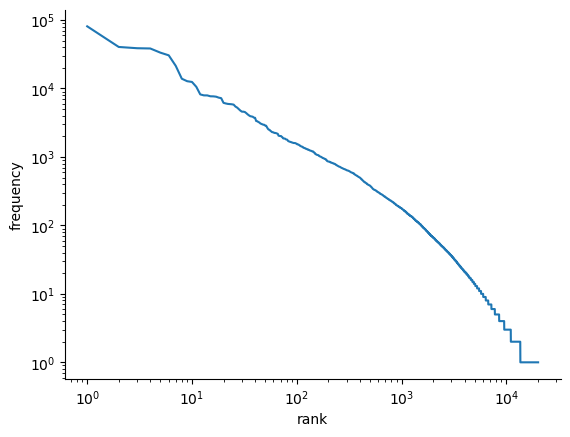

In [4]:
print(pb.sentence[3]); print(tok(pb.sentence[3]))
cnt_all = Counter(w for t in sp.contents for w in tok(t))
freq = np.array(sorted(cnt_all.values(), reverse=True), float); rk = np.arange(1, len(freq) + 1); s = (rk >= 10) & (rk <= 10000)
print('tokens', int(freq.sum()), 'types', len(freq), 'Zipf slope', round(np.polyfit(np.log(rk[s]), np.log(freq[s]), 1)[0], 3))
plt.loglog(rk, freq); plt.xlabel('rank'); plt.ylabel('frequency'); plt.show()

## §2 Our own word2vec on ECB speeches

Skip-gram with negative sampling: $\ell=-\log\sigma(\mathbf u_o^\top\mathbf v_w)-\sum_k\log\sigma(-\mathbf u_{n_k}^\top\mathbf v_w)$. Three epochs here (five on the slides).

In [5]:
docs = [tok(t) for t in sp.contents]
cnt = Counter(w for d in docs for w in d)
vocab = [w for w, c in cnt.most_common() if c >= 5]; w2i = {w: i for i, w in enumerate(vocab)}; V = len(vocab)
counts = np.array([cnt[w] for w in vocab], float); f = counts / counts.sum()
keep = np.minimum(1, np.sqrt(1e-4 / f) + 1e-4 / f)
ids = [np.array([w2i[w] for w in d if w in w2i]) for d in docs]
rng = np.random.RandomState(SEED); torch.manual_seed(SEED)
DIM, WIN, NEG = 100, 5, 5
Win, Wout = nn.Embedding(V, DIM), nn.Embedding(V, DIM)
nn.init.uniform_(Win.weight, -.5 / DIM, .5 / DIM); nn.init.zeros_(Wout.weight)
noise = torch.tensor(counts ** .75 / (counts ** .75).sum(), dtype=torch.float)
opt = torch.optim.Adam(list(Win.parameters()) + list(Wout.parameters()), lr=0.003)
for ep in range(3):
    cen, ctx = [], []
    for d in ids:
        d = d[rng.rand(len(d)) < keep[d]]
        for off in range(1, WIN + 1):
            if off >= len(d): break
            b = rng.randint(1, WIN + 1, len(d) - off) >= off
            cen += [d[:-off][b], d[off:][b]]; ctx += [d[off:][b], d[:-off][b]]
    cen, ctx = torch.tensor(np.concatenate(cen)), torch.tensor(np.concatenate(ctx)); perm = torch.randperm(len(cen)); tot = 0
    for j in range(0, len(perm), 4096):
        b = perm[j:j + 4096]; v = Win(cen[b]); ng = torch.multinomial(noise, len(b) * NEG, replacement=True).view(len(b), NEG)
        loss = -(F.logsigmoid((v * Wout(ctx[b])).sum(1)) + F.logsigmoid(-(Wout(ng) @ v.unsqueeze(2)).squeeze(2)).sum(1)).mean()
        opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss)
    print('epoch', ep + 1, 'loss', round(tot / (len(perm) / 4096), 3), 'pairs', len(cen))
E = Win.weight.detach().numpy(); En = E / np.linalg.norm(E, axis=1, keepdims=True)
def nearest(w, k=5):
    s = En @ En[w2i[w]]; s[w2i[w]] = -1; return [(vocab[i], round(float(s[i]), 2)) for i in np.argsort(-s)[:k]]

epoch 1 loss 2.628 pairs 3678608


epoch 2 loss 2.364 pairs 3678478


epoch 3 loss 2.292 pairs 3678872


In [6]:
for w in ['inflation', 'energy', 'banks', 'climate', 'digital']:
    print(w, nearest(w))

inflation [('revert', 0.74), ('headline', 0.71), ('medium', 0.71), ('downwards', 0.7), ('reverting', 0.7)]
energy [('prices', 0.74), ('importer', 0.73), ('food', 0.73), ('imported', 0.73), ('fertilisers', 0.71)]
banks [('lend', 0.65), ('tolerance', 0.63), ('adequately', 0.63), ('optimise', 0.63), ('commensurate', 0.63)]
climate [('degradation', 0.75), ('environmental', 0.73), ('litigation', 0.73), ('nature', 0.73), ('change', 0.72)]


digital [('sphere', 0.73), ('wherever', 0.73), ('usable', 0.71), ('universally', 0.71), ('replicate', 0.69)]


## §3 Sentiment on the Financial PhraseBank

In [7]:
rs = np.random.RandomState(SEED); tr, va, te = [], [], []
for c in range(3):
    ids = rs.permutation(np.where(pb_y == c)[0]); n = len(ids)
    tr += list(ids[:int(.7 * n)]); va += list(ids[int(.7 * n):int(.85 * n)]); te += list(ids[int(.85 * n):])
tr, va, te = map(np.array, (tr, va, te))
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score
J = lambda ids: [' '.join(pb_tok[i]) for i in ids]
def lr_tuned(Xtr, ytr, Xva, yva, Xte):
    best = max(((f1_score(yva, LogisticRegression(C=C, max_iter=3000, class_weight='balanced').fit(Xtr, ytr).predict(Xva), average='macro'), C)
                for C in [0.1, 1.0, 10.0]))
    m = LogisticRegression(C=best[1], max_iter=3000, class_weight='balanced').fit(Xtr, ytr)
    return m.predict(Xte), m
print(len(tr), len(va), len(te))

3385 726 727


In [8]:
res = {}
maj = np.bincount(pb_y[tr]).argmax(); res['majority'] = np.full(len(te), maj)
bow = CountVectorizer(tokenizer=str.split, lowercase=False, token_pattern=None, min_df=2).fit(J(tr))
res['bow_lr'], mb = lr_tuned(bow.transform(J(tr)), pb_y[tr], bow.transform(J(va)), pb_y[va], bow.transform(J(te)))
tf = TfidfVectorizer(tokenizer=str.split, lowercase=False, token_pattern=None, ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(J(tr))
res['tfidf_lr'], _ = lr_tuned(tf.transform(J(tr)), pb_y[tr], tf.transform(J(va)), pb_y[va], tf.transform(J(te)))
me = lambda I: np.array([E[[w2i[w] for w in pb_tok[i] if w in w2i]].mean(0) if any(w in w2i for w in pb_tok[i]) else np.zeros(DIM) for i in I])
res['w2v_lr'], _ = lr_tuned(me(tr), pb_y[tr], me(va), pb_y[va], me(te))
for k, p in res.items():
    print(f'{k:10s} macro-F1 {100 * f1_score(pb_y[te], p, average="macro"):.2f}  accuracy {100 * accuracy_score(pb_y[te], p):.2f}')
voc = bow.get_feature_names_out(); d = mb.coef_[2] - mb.coef_[0]
print('positive:', list(voc[np.argsort(-d)[:8]])); print('negative:', list(voc[np.argsort(d)[:8]]))

majority   macro-F1 24.81  accuracy 59.28
bow_lr     macro-F1 68.56  accuracy 73.04
tfidf_lr   macro-F1 69.50  accuracy 74.42
w2v_lr     macro-F1 55.19  accuracy 60.39
positive: ['rose', 'increase', 'grew', 'up', 'improved', 'increased', 'positive', 'signed']
negative: ['decreased', 'down', 'fell', 'cut', 'dropped', 'declined', 'half', 'lay']


## §4 An embedding-bag network

$\mathbf z = \frac1{|S|}\sum_{s\in S}\mathbf e_s$, then a softmax layer; random start or start from our word2vec.

In [9]:
def embbag(init, dim=100, epochs=30):
    torch.manual_seed(SEED); np.random.seed(SEED)
    ng = lambda t: t + [a + '_' + b for a, b in zip(t, t[1:])]
    voc = {'<pad>': 0}
    if init:
        for w in vocab: voc[w] = len(voc)
    for w, k in Counter(x for i in tr for x in ng(pb_tok[i])).items():
        if k >= 2 and w not in voc: voc[w] = len(voc)
    emb = nn.EmbeddingBag(len(voc), dim, mode='mean'); out = nn.Linear(dim, 3)
    if init:
        with torch.no_grad(): emb.weight[1:V + 1] = torch.tensor(E / np.linalg.norm(E, axis=1, keepdims=True).mean())
    def enc(I):
        ids, offs = [], []
        for i in I:
            offs.append(len(ids)); ids += [voc[w] for w in ng(pb_tok[i]) if w in voc] or [0]
        return torch.tensor(ids), torch.tensor(offs)
    params = list(emb.parameters()) + list(out.parameters()); opt = torch.optim.Adam(params, lr=5e-3)
    w = torch.tensor(len(tr) / (3 * np.bincount(pb_y[tr])), dtype=torch.float); best, state, bad = -1, None, 0
    for ep in range(epochs):
        perm = np.random.permutation(tr)
        for j in range(0, len(perm), 64):
            b = perm[j:j + 64]; loss = F.cross_entropy(out(F.dropout(emb(*enc(b)), .3)), torch.tensor(pb_y[b]), weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): f = f1_score(pb_y[va], out(emb(*enc(va))).argmax(1).numpy(), average='macro')
        if f > best: best, bad, state = f, 0, ([p.clone() for p in params])
        else:
            bad += 1
            if bad >= 4: break
    with torch.no_grad():
        for p, q in zip(params, state): p.copy_(q)
        return out(emb(*enc(te))).argmax(1).numpy()
for init in (False, True):
    p = embbag(init); print('embedding bag', 'word2vec start' if init else 'random start', 'macro-F1', round(100 * f1_score(pb_y[te], p, average='macro'), 2))

embedding bag random start macro-F1 67.0


embedding bag word2vec start macro-F1 66.58


## §5 Topics of finance tweets

In [10]:
tp = pd.read_csv(DATA + 'twitter_fin_topic.csv'); a, b = tp[tp.split == 'train'], tp[tp.split == 'valid']
tf2 = TfidfVectorizer(tokenizer=tok, lowercase=False, token_pattern=None, ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(a.text)
m = LogisticRegression(C=10, max_iter=3000, class_weight='balanced').fit(tf2.transform(a.text), a.label)
p = m.predict(tf2.transform(b.text))
print('topic macro-F1', round(100 * f1_score(b.label, p, average='macro'), 2), ' accuracy', round(100 * accuracy_score(b.label, p), 2))

topic macro-F1 83.23  accuracy 84.96
